# PBMC Data import

Status	Public on Oct 11, 2026
Title	PBMC scRNA-seq from HC 01
Sample type	SRA
 	
Source name	Peripheral blood
Organism	Homo sapiens
Characteristics	tissue: Peripheral blood
cell type: Peripheral blood mononuclear cells (PBMCs)
Extracted molecule	total RNA
Extraction protocol	Peripheral blood mononuclear cells (PBMCs) were isolated from EDTA-anticoagulated venous blood. Briefly, blood was diluted with an equal volume of PBS, layered over Ficoll separation medium, and centrifuged (500 × g, 30 min). PBMCs were collected, washed, and subjected to red blood cell lysis. The final cell pellet was resuspended in 0.04% BSA/PBS and adjusted to a concentration of 700–1200 cells/μL to prepare a single-cell suspension.
Single-cell RNA-seq libraries were prepared using the 10x Genomics Chromium Single Cell 5′ Reagent Kit v2 following the manufacturer’s protocol. TCR and BCR V(D)J libraries were generated using the 10x Genomics TCR/BCR Amplification Kit.
 	
Library strategy	RNA-Seq
Library source	transcriptomic single cell
Library selection	cDNA
Instrument model	Illumina NovaSeq 6000
 	
Description	Library name: HC_PBMC_01
10x Genomics .
Data processing	Raw FASTQ files were processed using Cell Ranger (v4.3.0) for alignment, barcode processing, and UMI quantification against the GRCh38 human reference genome.
Gene expression matrices were analyzed using Seurat (v4.3.0). Cells with <300 or >7,000 genes, mitochondrial content >20%, hemoglobin content >5%, or UMI counts >20,000 were removed. Doublets were filtered using DoubletFinder.
Assembly: GRCh38 (hg38)
Supplementary files format and content: 10x Genomics filtered gene-barcode matrices containing UMI counts for each gene in each cell (barcodes.tsv.gz, features.tsv.gz, matrix.mtx.gz).

In [3]:

import scanpy as sc
import pandas as pd
import anndata as ad
import requests
import gzip
import io
from scipy.io import mmread

base_url = "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM9453nnn"

samples = {
    "GSM9453841": "HC01",
    "GSM9453842": "HC02",
    "GSM9453843": "HC03"
}

adatas = []

for gsm, sample in samples.items():
    url = f"{base_url}/{gsm}/suppl/{gsm}_{sample}_scRNAseq_all_cells_"

    matrix_response = requests.get(url + "matrix.mtx.gz")
    matrix_response.raise_for_status()

    features_response = requests.get(url + "features.tsv.gz")
    features_response.raise_for_status()

    barcodes_response = requests.get(url + "barcodes.tsv.gz")
    barcodes_response.raise_for_status()

    matrix = gzip.GzipFile(fileobj=io.BytesIO(matrix_response.content))
    X = mmread(matrix).T.tocsr()

    features = pd.read_csv(
        gzip.GzipFile(fileobj=io.BytesIO(features_response.content)),
        sep="\t",
        header=None
    )

    barcodes = pd.read_csv(
        gzip.GzipFile(fileobj=io.BytesIO(barcodes_response.content)),
        sep="\t",
        header=None
    )

    if X.shape != (len(barcodes), len(features)):
        raise ValueError(
            f"{gsm}: matrix shape {X.shape}, "
            f"barcodes {len(barcodes)}, features {len(features)}"
        )

    temp = ad.AnnData(X=X)
    temp.var_names = features.iloc[:, 0].astype(str).values
    temp.obs_names = barcodes.iloc[:, 0].astype(str).values

    temp.var_names_make_unique()
    temp.obs_names = [f"{gsm}_{barcode}" for barcode in temp.obs_names]

    temp.obs["batch"] = gsm
    temp.obs["sample_id"] = sample

    adatas.append(temp)

adata = ad.concat(
    adatas,
    join="outer",
    merge="same",
    index_unique=None
)

adata.obs["batch"] = adata.obs["batch"].astype("category")
adata.obs["sample_id"] = adata.obs["sample_id"].astype("category")

print(adata)
print(adata.obs["batch"].value_counts())


AnnData object with n_obs × n_vars = 38560 × 36601
    obs: 'batch', 'sample_id'
batch
GSM9453841    13968
GSM9453843    13864
GSM9453842    10728
Name: count, dtype: int64


In [4]:
# Reuse the original features table: column 0 = Ensembl ID, column 1 = gene symbol.
if features.shape[1] < 2:
    raise ValueError("The features table must contain Ensembl IDs and gene symbols.")

symbol_map = features.set_index(0)[1]
if not symbol_map.index.is_unique:
    raise ValueError("The features table contains duplicate Ensembl IDs.")

if "ensembl_id" in adata.var.columns:
    ensembl_ids = adata.var["ensembl_id"].copy()
else:
    ensembl_ids = pd.Series(adata.var_names, index=adata.var_names)

gene_symbols = ensembl_ids.map(symbol_map).replace("", pd.NA)
if not gene_symbols.notna().any():
    raise ValueError("No Ensembl IDs matched the features table.")

adata.var["ensembl_id"] = ensembl_ids
adata.var["gene_symbol"] = gene_symbols
adata.var_names = pd.Index(gene_symbols.fillna(ensembl_ids).astype(str)).rename(
    adata.var_names.name
)
adata.var_names_make_unique()

print(f"Mapped {gene_symbols.notna().sum():,} / {adata.n_vars:,} genes to symbols.")
print(f"Unmapped genes retain their Ensembl IDs: {gene_symbols.isna().sum():,}")
adata.var.head()

Mapped 36,601 / 36,601 genes to symbols.
Unmapped genes retain their Ensembl IDs: 0


,ensembl_id,gene_symbol
MIR1302-2HG,ENSG00000243485,MIR1302-2HG
FAM138A,ENSG00000237613,FAM138A
OR4F5,ENSG00000186092,OR4F5
AL627309.1,ENSG00000238009,AL627309.1
AL627309.3,ENSG00000239945,AL627309.3


In [5]:
bdata = adata.copy()

# Preprocess (adata)

In [6]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
adata.var["hb"] = adata.var_names.str.startswith(("HBA", "HBB"))

sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True
)

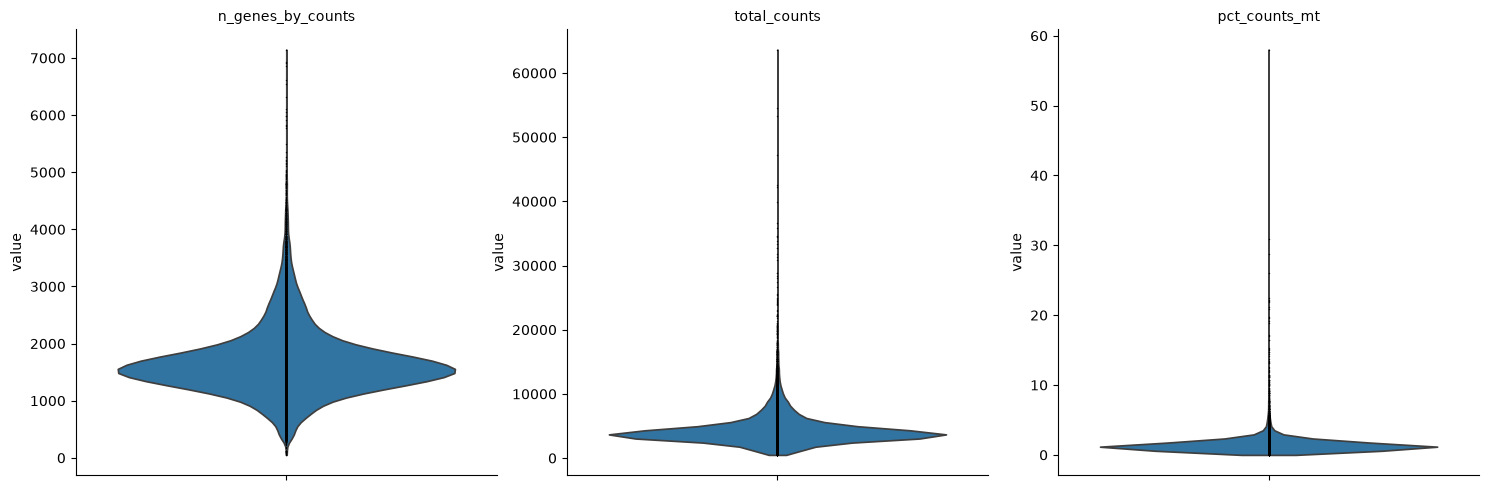

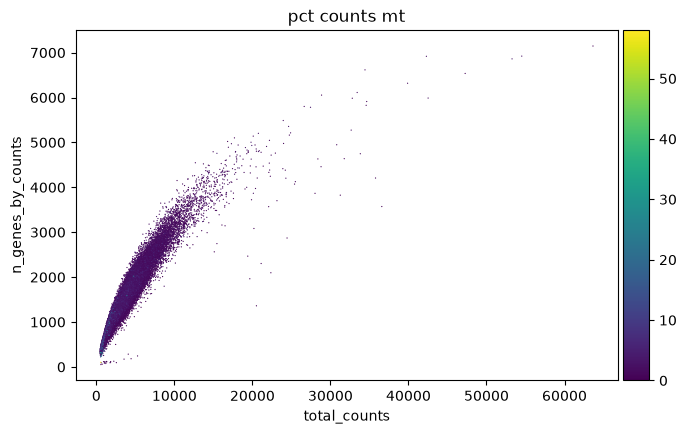

In [7]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.0,
    multi_panel=True,
)
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

In [8]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

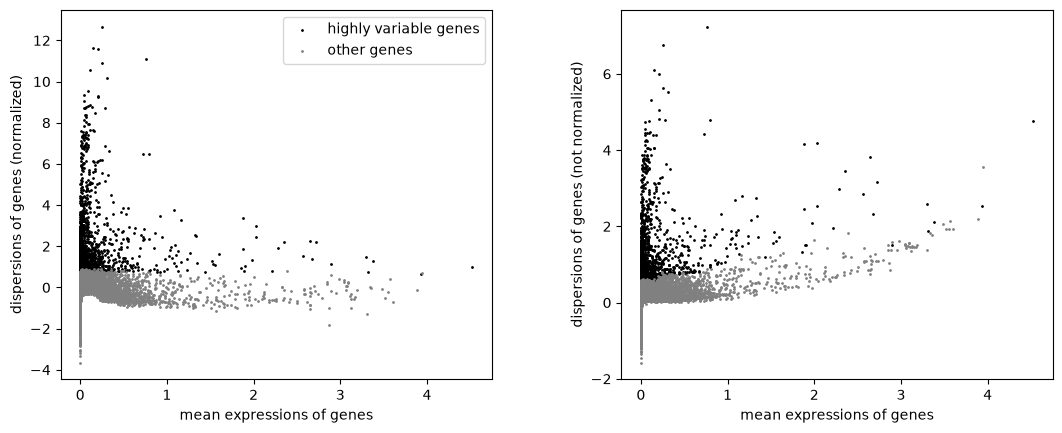

In [9]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="sample_id")
sc.pl.highly_variable_genes(adata)

In [10]:
adata = adata[:, adata.var['highly_variable']].copy()

# Clustering

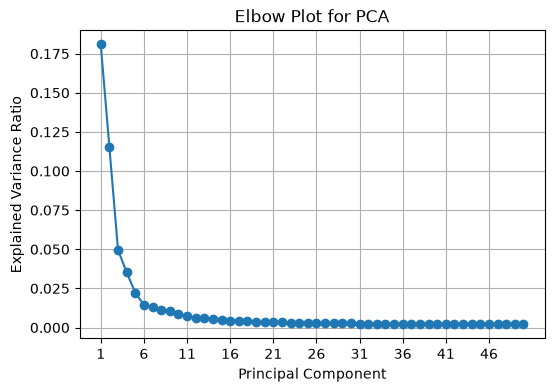

In [11]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

sc.tl.pca(adata)
explained_variance_ratio = adata.uns["pca"]["variance_ratio"]

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, marker="o", linestyle="-")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Elbow Plot for PCA")
plt.xticks(np.arange(1, len(explained_variance_ratio) + 1, step=5))
plt.grid()
plt.show()

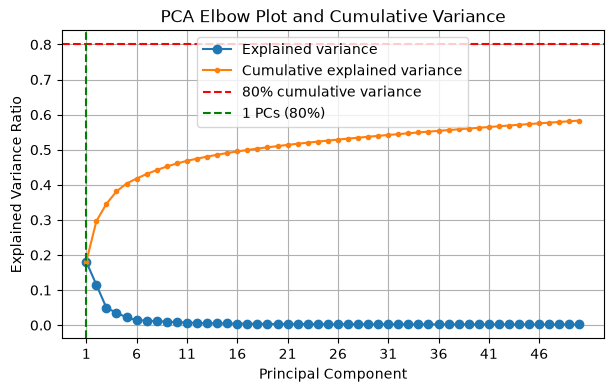

Number of PCs required to explain at least 80% variance: 1
Cumulative explained variance: 0.1809


In [12]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

sc.tl.pca(adata)

explained_variance_ratio = adata.uns["pca"]["variance_ratio"]
cumulative_variance = np.cumsum(explained_variance_ratio)
n_components = np.argmax(cumulative_variance >= 0.8) + 1

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, marker="o", linestyle="-", label="Explained variance")
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker=".", linestyle="-", label="Cumulative explained variance")
plt.axhline(y=0.8, color="red", linestyle="--", label="80% cumulative variance")
plt.axvline(x=n_components, color="green", linestyle="--", label=f"{n_components} PCs (80%)")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Elbow Plot and Cumulative Variance")
plt.xticks(np.arange(1, len(explained_variance_ratio) + 1, step=5))
plt.grid()
plt.legend()
plt.show()

print(f"Number of PCs required to explain at least 80% variance: {n_components}")
print(f"Cumulative explained variance: {cumulative_variance[n_components - 1]:.4f}")

In [12]:
sc.tl.pca(adata, n_comps=16)

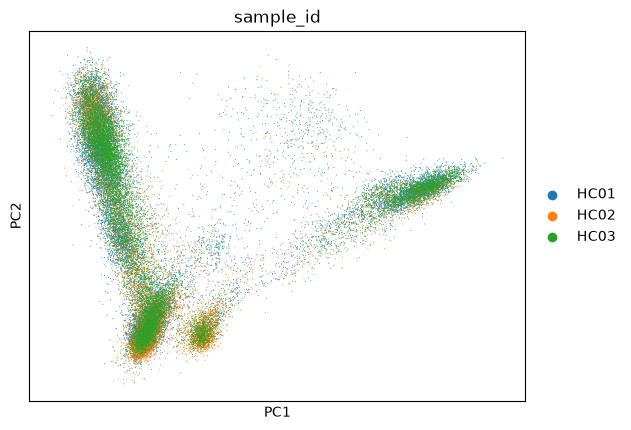

In [13]:
sc.pl.pca(
    adata,
    color=["sample_id"],
    ncols=2,
    size=2,
)

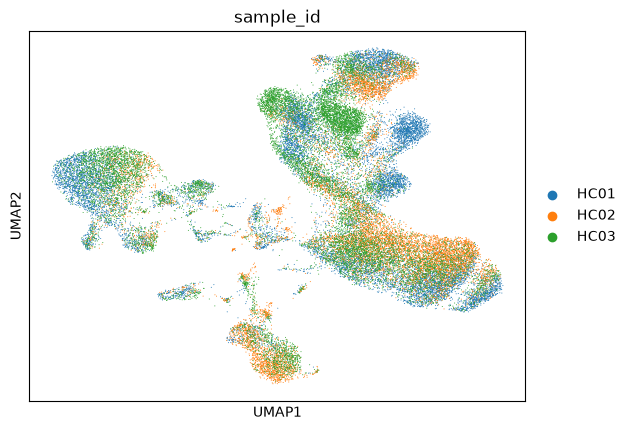

In [14]:
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.pl.umap(
    adata,
    color="sample_id",
    # Setting a smaller point size to get prevent overlap
    size=2,
)

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA RTX A5000') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/home/Dat

Training:   0%|          | 0/200 [00:00<?, ?it/s]

Monitored metric elbo_validation did not improve in the last 5 records. Best score: 403.974. Signaling Trainer to stop.


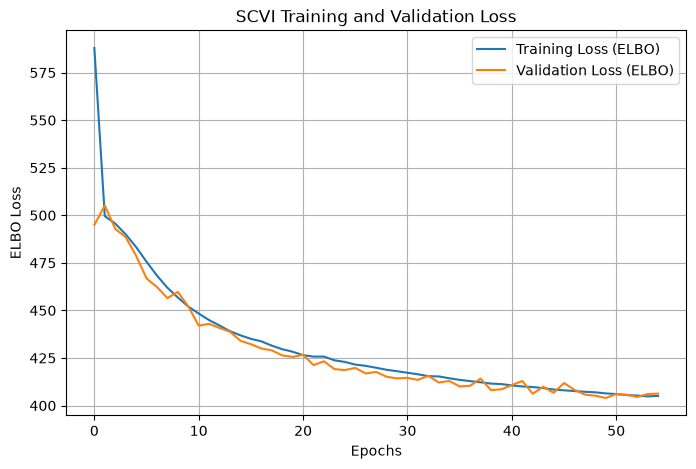

In [15]:
import scvi 
import matplotlib.pyplot as plt

scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="sample_id")
vae = scvi.model.SCVI(adata, n_layers=2, n_latent=30, gene_likelihood="nb")

vae.train(max_epochs=200, early_stopping=True, early_stopping_patience=5)

train_loss = vae.history["elbo_train"]
val_loss = vae.history["elbo_validation"]
plt.figure(figsize=(8, 5))
plt.plot(train_loss, label="Training Loss (ELBO)")
plt.plot(val_loss, label="Validation Loss (ELBO)")
plt.xlabel("Epochs")
plt.ylabel("ELBO Loss")
plt.title("SCVI Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

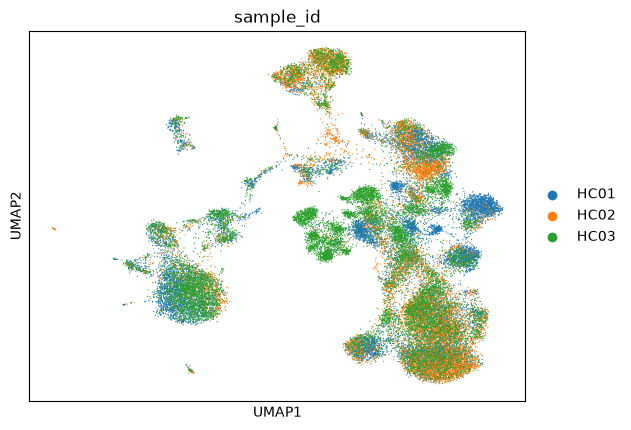

In [16]:
adata.obsm["X_scVI"] = vae.get_latent_representation()
sc.pp.neighbors(adata, use_rep = 'X_scVI')
sc.tl.umap(adata)

sc.pl.umap(adata, color=["sample_id"])

In [17]:
for res in [0.25 , 0.5, 0.75, 1]:
    sc.tl.leiden(
        adata, key_added=f"leiden_res_{res:4.2f}", resolution=res, flavor="igraph"
    )

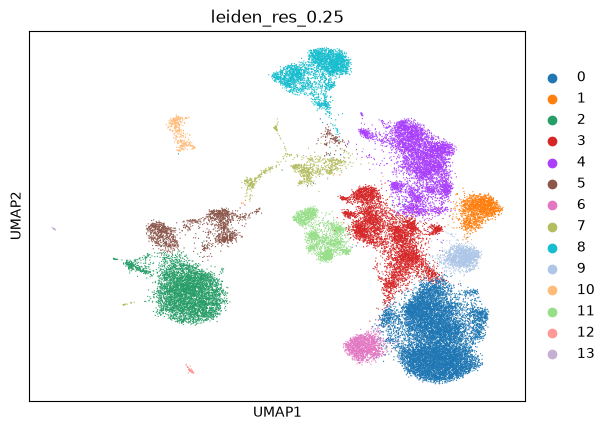

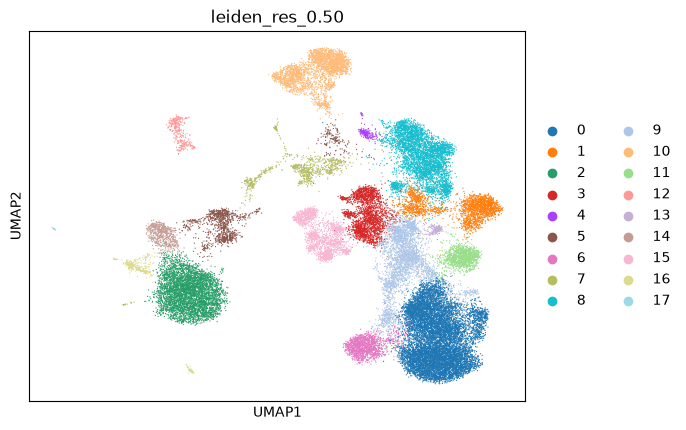

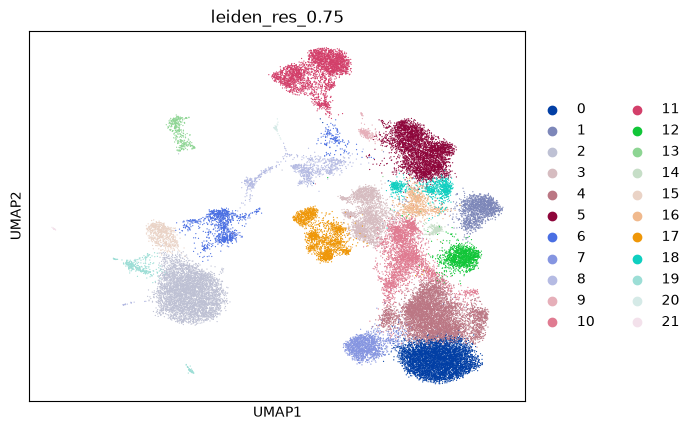

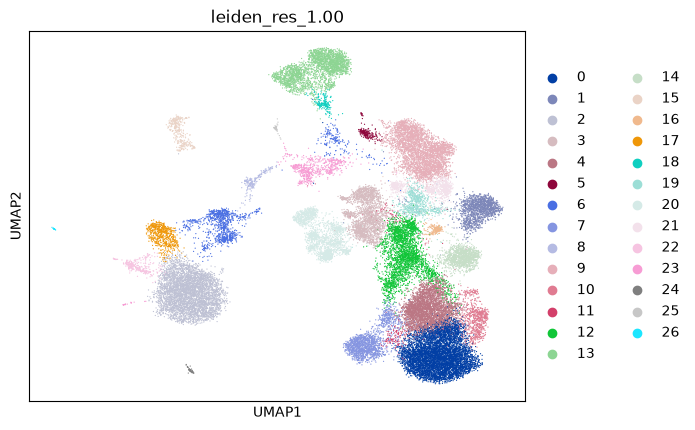

In [18]:
sc.pl.umap(adata, color=["leiden_res_0.25"])
sc.pl.umap(adata, color=["leiden_res_0.50"])
sc.pl.umap(adata, color=["leiden_res_0.75"])
sc.pl.umap(adata, color=["leiden_res_1.00"])

In [19]:
import scanpy as sc
sc.tl.rank_genes_groups(adata, groupby='leiden_res_0.50', method='t-test')  # 또는 'wilcoxon'
top_genes = {}
groups = adata.uns['rank_genes_groups']['names'].dtype.names  # 클러스터 이름들
for group in groups:
    genes = adata.uns['rank_genes_groups']['names'][group][:20]
    top_genes[group] = genes.tolist()

for cluster, genes in top_genes.items():
    print(f"Cluster {cluster}: {genes}")

Cluster 0: ['LTB', 'RPL32', 'TCF7', 'IL7R', 'LEF1', 'CCR7', 'CAMK4', 'INPP4B', 'AQP3', 'SELL', 'IFITM1', 'TSHZ2', 'PDE3B', 'BCL2', 'CRIP2', 'AC139720.1', 'PLCL1', 'FHIT', 'BEX3', 'FOXP1']
Cluster 1: ['NKG7', 'CCL5', 'GNLY', 'B2M', 'CST7', 'TRGV9', 'TRDV2', 'HLA-B', 'CTSW', 'GZMA', 'PRF1', 'KLRD1', 'KLRG1', 'IFITM1', 'S100B', 'HOPX', 'TRBC1', 'CD247', 'TRDC', 'TRGV8']
Cluster 2: ['LYZ', 'FTL', 'TYROBP', 'S100A9', 'CST3', 'IFI30', 'S100A8', 'S100A6', 'FTH1', 'CTSS', 'AIF1', 'FCN1', 'LST1', 'S100A11', 'PSAP', 'COTL1', 'S100A4', 'SPI1', 'VCAN', 'MNDA']
Cluster 3: ['NKG7', 'CCL5', 'GNLY', 'GZMH', 'B2M', 'CST7', 'CD8A', 'FGFBP2', 'CD8B', 'GZMB', 'GZMA', 'PRF1', 'S100A4', 'CTSW', 'KLRD1', 'HLA-B', 'KLRK1', 'EFHD2', 'IFITM1', 'TMSB4X']
Cluster 4: ['CTSW', 'GNLY', 'SELL', 'TYROBP', 'GZMK', 'FCER1G', 'IL2RB', 'CD7', 'XCL1', 'IFITM3', 'HOPX', 'CMC1', 'KLRD1', 'XCL2', 'NKG7', 'IFITM1', 'KLRF1', 'TRDC', 'KLRC1', 'KLRB1']
Cluster 5: ['TYROBP', 'S100A9', 'CST3', 'FTL', 'LYZ', 'IFI30', 'S100A8', 'AIF1

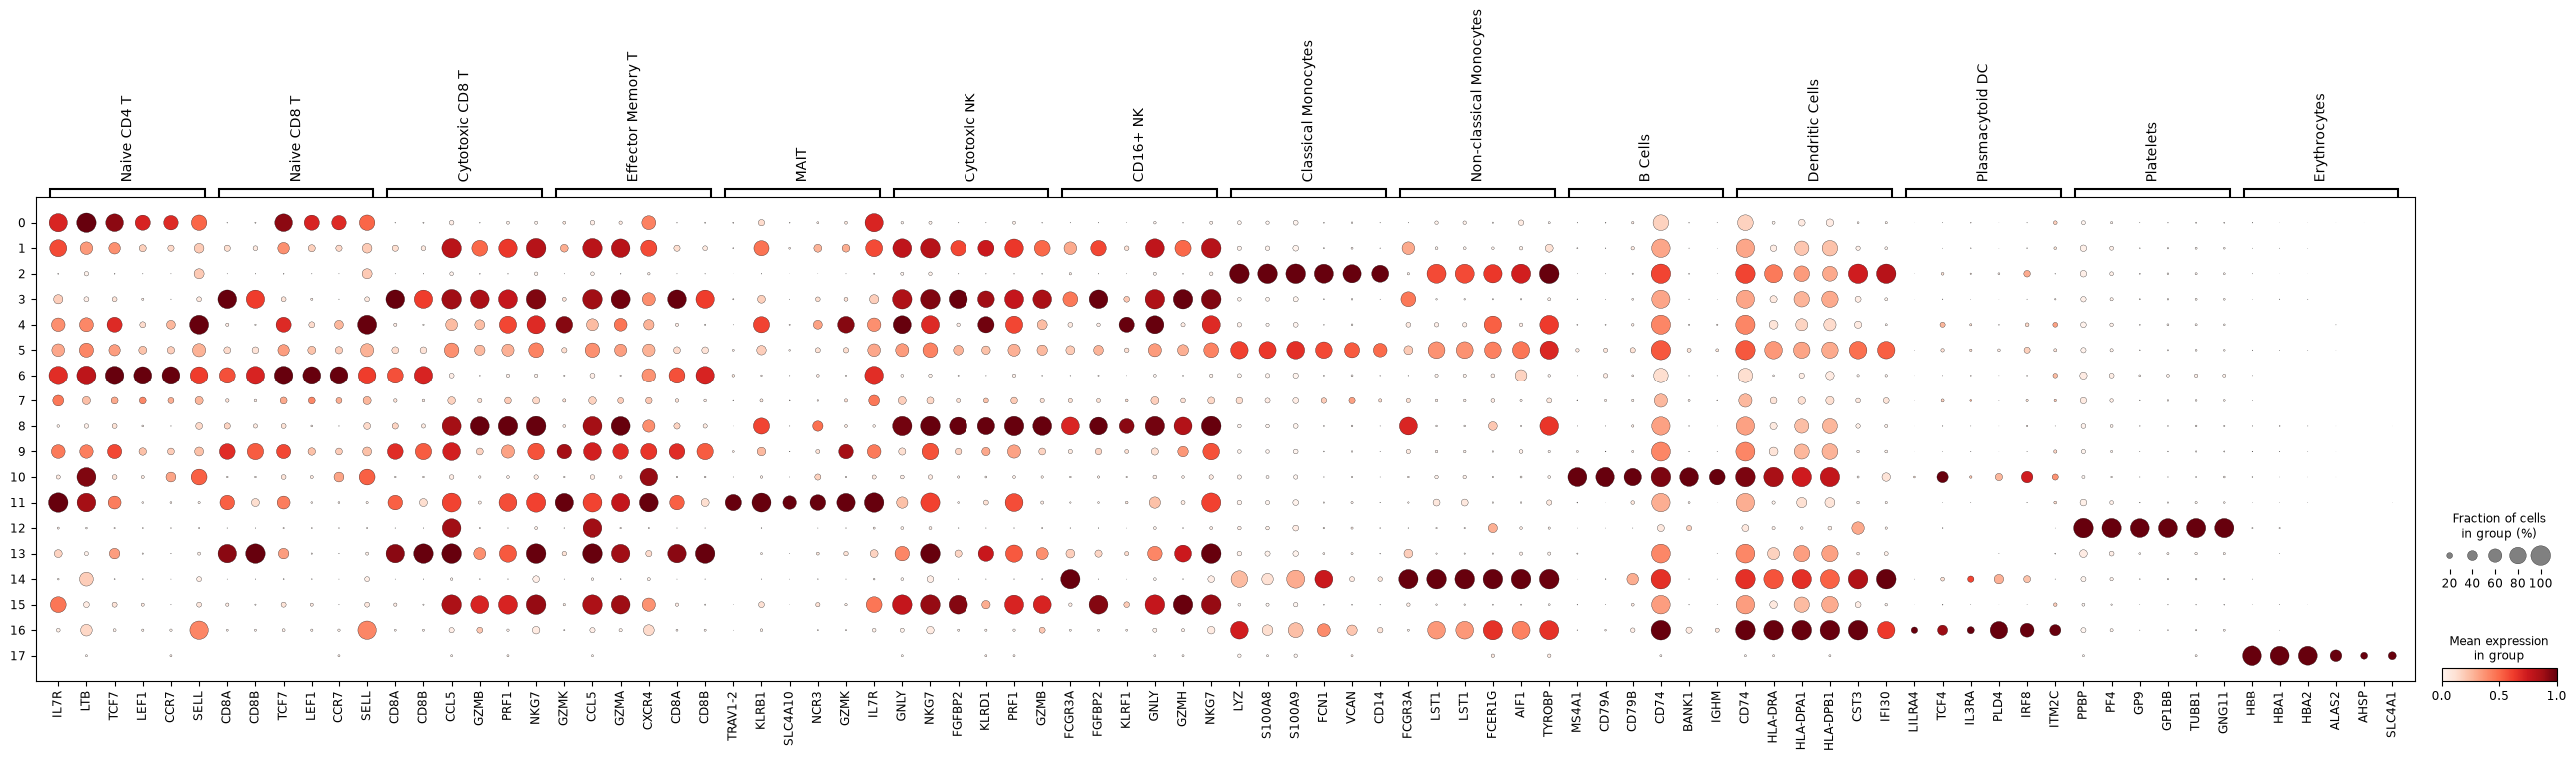

In [20]:
PBMC_subtype_markers_human = {
    "Naive CD4 T": [
        "IL7R", "LTB", "TCF7", "LEF1", "CCR7", "SELL"
    ],
    "Naive CD8 T": [
        "CD8A", "CD8B", "TCF7", "LEF1", "CCR7", "SELL"
    ],
    "Cytotoxic CD8 T": [
        "CD8A", "CD8B", "CCL5", "GZMB", "PRF1", "NKG7"
    ],
    "Effector Memory T": [
        "GZMK", "CCL5", "GZMA", "CXCR4", "CD8A", "CD8B"
    ],
    "MAIT": [
        "TRAV1-2", "KLRB1", "SLC4A10", "NCR3", "GZMK", "IL7R"
    ],
    "Cytotoxic NK": [
        "GNLY", "NKG7", "FGFBP2", "KLRD1", "PRF1", "GZMB"
    ],
    "CD16+ NK": [
        "FCGR3A", "FGFBP2", "KLRF1", "GNLY", "GZMH", "NKG7"
    ],
    "Classical Monocytes": [
        "LYZ", "S100A8", "S100A9", "FCN1", "VCAN", "CD14"
    ],
    "Non-classical Monocytes": [
        "FCGR3A", "LST1", "LST1", "FCER1G", "AIF1", "TYROBP"
    ],
    "B Cells": [
        "MS4A1", "CD79A", "CD79B", "CD74", "BANK1", "IGHM"
    ],
    "Dendritic Cells": [
        "CD74", "HLA-DRA", "HLA-DPA1", "HLA-DPB1", "CST3", "IFI30"
    ],
    "Plasmacytoid DC": [
        "LILRA4", "TCF4", "IL3RA", "PLD4", "IRF8", "ITM2C"
    ],
    "Platelets": [
        "PPBP", "PF4", "GP9", "GP1BB", "TUBB1", "GNG11"
    ],
    "Erythrocytes": [
        "HBB", "HBA1", "HBA2", "ALAS2", "AHSP", "SLC4A1"
    ]
}

existing_subtype_markers = {
    subtype: [gene for gene in genes if gene in adata.var_names]
    for subtype, genes in PBMC_subtype_markers_human.items()
}

existing_subtype_markers = {
    subtype: genes
    for subtype, genes in existing_subtype_markers.items()
    if genes
}

sc.pl.dotplot(
    adata,
    var_names=existing_subtype_markers,
    groupby="leiden_res_0.50",
    standard_scale="var",
    dendrogram=False
)

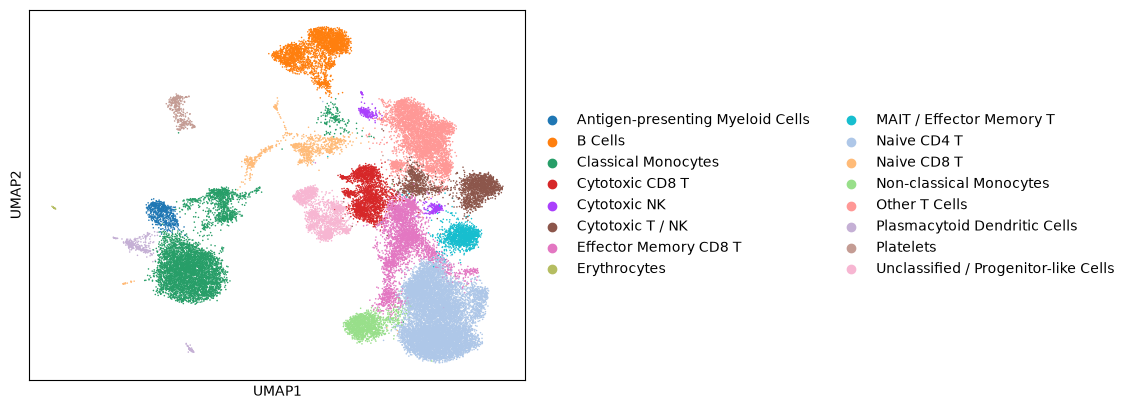

In [21]:
import scanpy as sc

cluster_to_group = {
    0: "Naive CD4 T",
    1: "Cytotoxic T / NK",
    2: "Classical Monocytes",
    3: "Cytotoxic CD8 T",
    4: "Cytotoxic NK",
    5: "Classical Monocytes",
    6: "Non-classical Monocytes",
    7: "Naive CD8 T",
    8: "Other T Cells",
    9: "Effector Memory CD8 T",
    10: "B Cells",
    11: "MAIT / Effector Memory T",
    12: "Platelets",
    13: "Cytotoxic NK",
    14: "Antigen-presenting Myeloid Cells",
    15: "Unclassified / Progenitor-like Cells",
    16: "Plasmacytoid Dendritic Cells",
    17: "Erythrocytes"
}

adata.obs["subtype"] = (
    adata.obs["leiden_res_0.50"].astype(int).map(cluster_to_group)
)

sc.pl.umap(
    adata,
    color="subtype",
    title="",
    s=5
)

In [22]:
import celltypist
from celltypist import models

models.download_models(force_update = True)
models.models_description()

/home/Data_Drive_8TB/kykim/.conda/envs/scrna/lib/python3.11/site-packages/celltypist/classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv
📜 Retrieving model list from server https://celltypist.cog.sanger.ac.uk/models/models.json
📚 Total models in list: 61
📂 Storing models in /home/Data_Drive_8TB/kykim/.celltypist/data/models
💾 Downloading model [1/61]: Immune_All_Low.pkl
💾 Downloading model [2/61]: Immune_All_High.pkl
💾 Downloading model [3/61]: Adult_COVID19_PBMC.pkl
💾 Downloading model [4/61]: Adult_CynomolgusMacaque_Hippocampus.pkl
💾 Downloading model [5/61]: Adult_Human_MTG.pkl
💾 Downloading model [6/61]: Adult_Human_PancreaticIslet.pkl
💾 Downloading model [7/61]: Adult_Human_PrefrontalCortex.pkl
💾 Downloading model [8/61]: Adult_Human_Skin.pkl
💾 Downloading model [9/61]: Adult_Human_Vascular.pkl
💾 Downloading model [10/61]: Adult_Mouse_Gut.pkl
💾 Downloading model [11/61]: Adult_Mous

,model,description
0,Immune_All_Low.pkl,immune sub-populations combined from 20 tissue...
1,Immune_All_High.pkl,immune populations combined from 20 tissues of...
2,Adult_COVID19_PBMC.pkl,peripheral blood mononuclear cell types from C...
3,Adult_CynomolgusMacaque_Hippocampus.pkl,cell types from the hippocampus of adult cynom...
4,Adult_Human_MTG.pkl,cell types and subtypes (10x-based) from the a...
...,...,...
56,Nuclei_Lung_Airway.pkl,cell populations from snRNA-seq of five locati...
57,PaediatricAdult_COVID19_Airway.pkl,cell types in the airway of paediatric and adu...
58,PaediatricAdult_COVID19_PBMC.pkl,peripheral blood mononuclear cell types of pae...
59,Pan_Fetal_Human.pkl,stromal and immune populations from the human ...


In [245]:
model = models.Model.load(model = 'Adult_COVID19_PBMC.pkl')
model.cell_types

array(['Activated Granulocyte', 'B', 'CD14 Monocyte', 'CD16 Monocyte',
       'CD4 T', 'CD4m T', 'CD4n T', 'CD8eff T', 'CD8m T',
       'Class-switched B', 'DC', 'IgA PB', 'IgG PB', 'NK', 'Neutrophil',
       'Platelet', 'RBC', 'SC & Eosinophil', 'gd T', 'pDC'], dtype=object)

In [246]:
adata.X = adata.layers['counts'].copy()

In [247]:
import scanpy as sc
import celltypist

adata.layers["counts"] = adata.X.copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

predictions = celltypist.annotate(
    adata,
    model="Adult_COVID19_PBMC.pkl",
    majority_voting=True
)

🔬 Input data has 38560 cells and 2000 genes
🔗 Matching reference genes in the model
🧬 688 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 15
🗳️ Majority voting the predictions
✅ Majority voting done!


In [248]:
adata.X.max()

np.float32(7.6228895)

In [249]:
adata = predictions.to_adata()

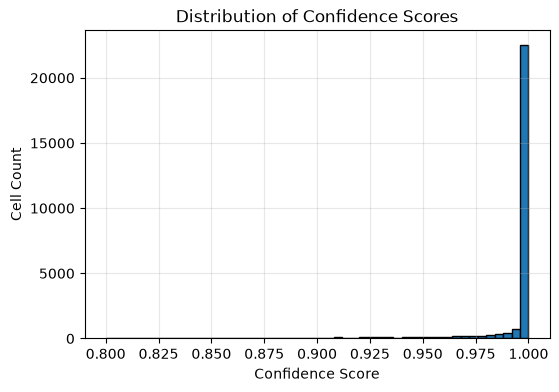

In [250]:
import matplotlib.pyplot as plt

cdata = adata[adata.obs["conf_score"] > 0.80].copy()

plt.figure(figsize=(6, 4))
plt.hist(cdata.obs["conf_score"].dropna(), bins=50, edgecolor="black")
plt.xlabel("Confidence Score")
plt.ylabel("Cell Count")
plt.title("Distribution of Confidence Scores")
plt.grid(alpha=0.3)
plt.show()

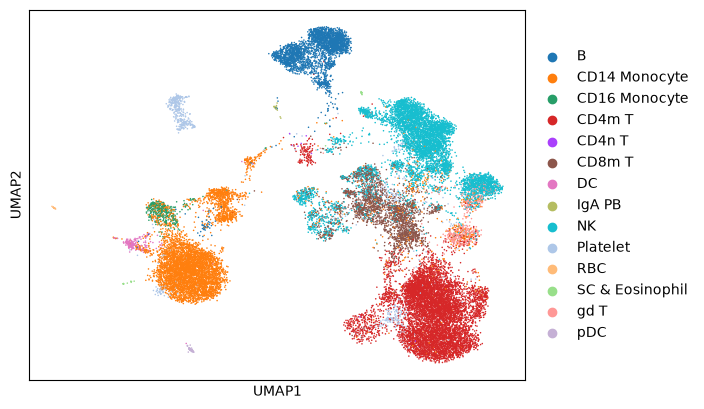

predicted_labels
CD4m T             7983
NK                 6355
CD14 Monocyte      6021
B                  2893
CD8m T             2284
Platelet            833
gd T                484
CD16 Monocyte       347
DC                  205
pDC                  50
SC & Eosinophil      23
RBC                  22
IgA PB               15
CD4n T               11
Name: count, dtype: int64

In [251]:
sc.pl.umap(
    cdata,
    color=["predicted_labels"],
    title="",
    s=5)

cdata.obs['predicted_labels'].value_counts()

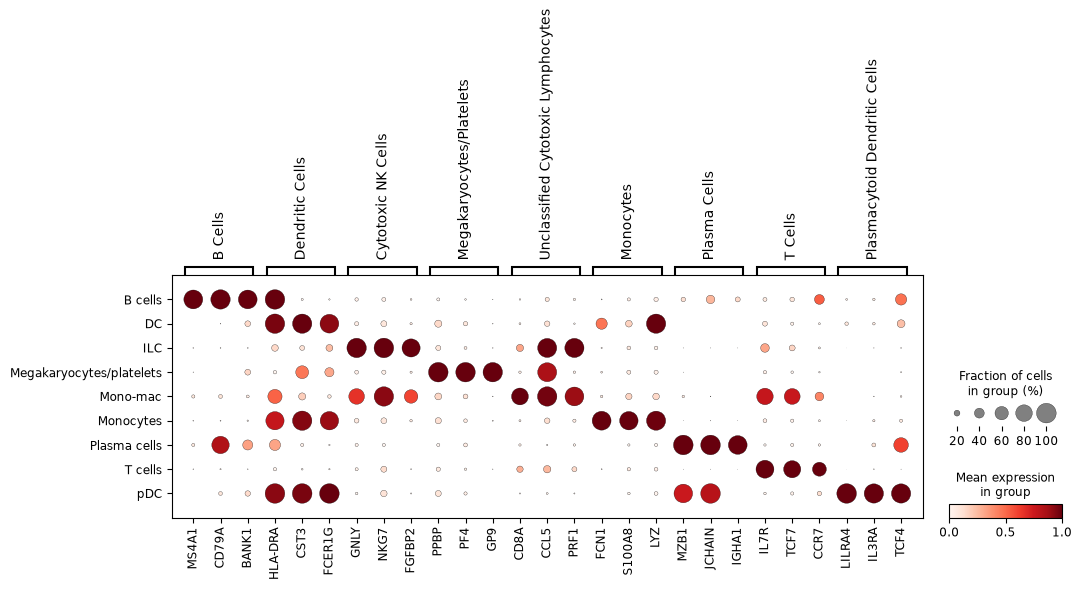

In [70]:
PBMC_subtype_markers_human = {
    "B Cells": ["MS4A1", "CD79A", "BANK1"],
    "Dendritic Cells": ["HLA-DRA", "CST3", "FCER1G"],
    "Cytotoxic NK Cells": ["GNLY", "NKG7", "FGFBP2"],
    "Megakaryocytes/Platelets": ["PPBP", "PF4", "GP9"],
    "Unclassified Cytotoxic Lymphocytes": ["CD8A", "CCL5", "PRF1"],
    "Monocytes": ["FCN1", "S100A8", "LYZ"],
    "Plasma Cells": ["MZB1", "JCHAIN", "IGHA1"],
    "T Cells": ["IL7R", "TCF7", "CCR7"],
    "Plasmacytoid Dendritic Cells": ["LILRA4", "IL3RA", "TCF4"]
}

existing_subtype_markers = {
    subtype: [gene for gene in genes if gene in cdata.var_names]
    for subtype, genes in PBMC_subtype_markers_human.items()
}

sc.pl.dotplot(
    cdata,
    var_names=existing_subtype_markers,
    groupby="predicted_labels",
    standard_scale="var",
    dendrogram=False
)

In [270]:
tdata = cdata[cdata.obs['predicted_labels'].isin([
    'CD4m T',
    'CD4n T',
    'CD8m T',
    'gd T'
])].copy()

tdata.obs['T_cell_type_large'] = tdata.obs['predicted_labels'].map({
    'CD4m T': 'CD4 T',
    'CD4n T': 'CD4 T',
    'CD8m T': 'CD8 T',
    'gd T': 'Other T'
})

In [271]:
common_cells = tdata.obs_names.intersection(bdata.obs_names)

labels = tdata.obs.loc[common_cells, 'predicted_labels']
cell_types = tdata.obs.loc[common_cells, 'T_cell_type_large']

tdata = bdata[common_cells].copy()
tdata.obs['predicted_labels'] = labels
tdata.obs['T_cell_type_large'] = cell_types

In [272]:
tdata.layers["counts"] = tdata.X.copy()
sc.pp.normalize_total(tdata)
sc.pp.log1p(tdata)

... storing 'T_cell_type_large' as categorical
... storing 'gene_symbol' as categorical


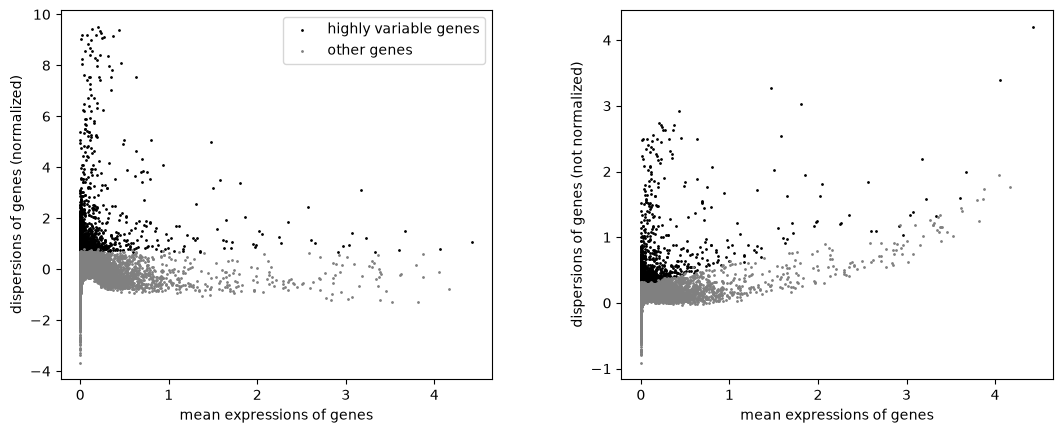

In [273]:
sc.pp.highly_variable_genes(tdata, n_top_genes=2000, batch_key="sample_id")
sc.pl.highly_variable_genes(tdata)

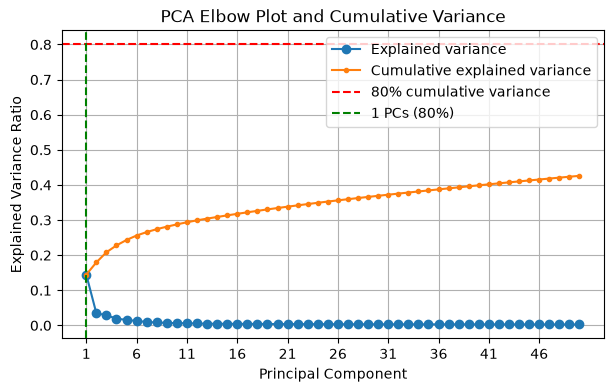

Number of PCs required to explain at least 80% variance: 1
Cumulative explained variance: 0.1447


In [274]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

sc.tl.pca(tdata)

explained_variance_ratio = tdata.uns["pca"]["variance_ratio"]
cumulative_variance = np.cumsum(explained_variance_ratio)
n_components = np.argmax(cumulative_variance >= 0.8) + 1

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, marker="o", linestyle="-", label="Explained variance")
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker=".", linestyle="-", label="Cumulative explained variance")
plt.axhline(y=0.8, color="red", linestyle="--", label="80% cumulative variance")
plt.axvline(x=n_components, color="green", linestyle="--", label=f"{n_components} PCs (80%)")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Elbow Plot and Cumulative Variance")
plt.xticks(np.arange(1, len(explained_variance_ratio) + 1, step=5))
plt.grid()
plt.legend()
plt.show()

print(f"Number of PCs required to explain at least 80% variance: {n_components}")
print(f"Cumulative explained variance: {cumulative_variance[n_components - 1]:.4f}")

In [275]:
sc.tl.pca(tdata, n_comps=46)

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Training:   0%|          | 0/200 [00:00<?, ?it/s]

Monitored metric elbo_validation did not improve in the last 20 records. Best score: 4712.953. Signaling Trainer to stop.


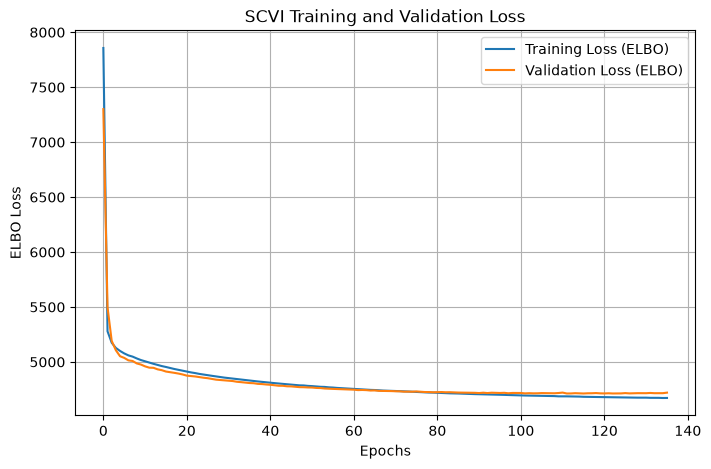

In [276]:
import scvi 
import matplotlib.pyplot as plt

scvi.model.SCVI.setup_anndata(tdata, layer="counts", batch_key="sample_id")
vae = scvi.model.SCVI(tdata, n_layers=2, n_latent=30, gene_likelihood="nb")

vae.train(max_epochs=200, early_stopping=True, early_stopping_patience=20)

train_loss = vae.history["elbo_train"]
val_loss = vae.history["elbo_validation"]
plt.figure(figsize=(8, 5))
plt.plot(train_loss, label="Training Loss (ELBO)")
plt.plot(val_loss, label="Validation Loss (ELBO)")
plt.xlabel("Epochs")
plt.ylabel("ELBO Loss")
plt.title("SCVI Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

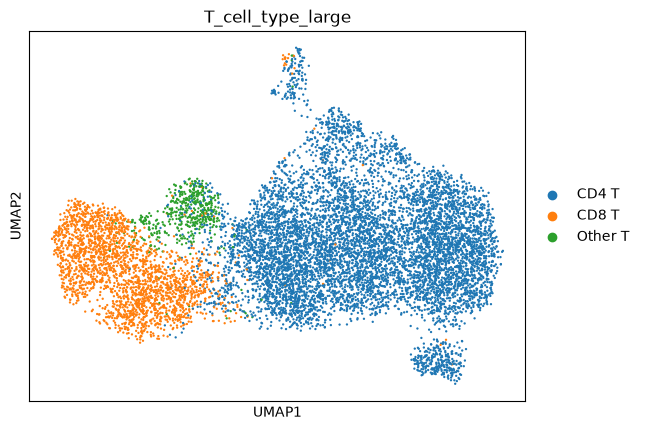

In [277]:
tdata.obsm["X_scVI"] = vae.get_latent_representation()
sc.pp.neighbors(tdata, use_rep = 'X_scVI')
sc.tl.umap(tdata)

sc.pl.umap(tdata, color=["T_cell_type_large"])

In [278]:
common_cells = tdata.obs_names.intersection(bdata.obs_names)
tdata = tdata[common_cells].copy()
tdata.X = bdata[common_cells, tdata.var_names].X.copy()

In [286]:
sc.pp.normalize_total(tdata, target_sum=1e4)
sc.pp.log1p(tdata)

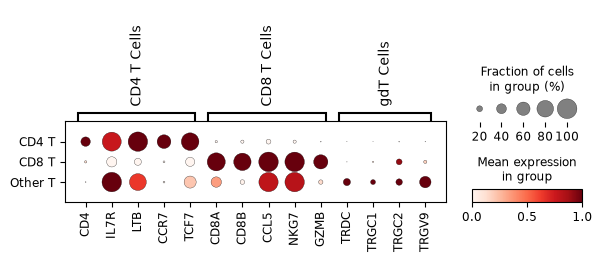

In [289]:
PBMC_subtype_markers_human = {
    "CD4 T Cells": ["CD4", "IL7R", "LTB", "CCR7", "TCF7"],
    "CD8 T Cells": ["CD8A", "CD8B", "CCL5", "NKG7", "GZMB"],
    "gdT Cells": ["TRDC", "TRGC1", "TRGC2", "TRGV9"]
}

existing_subtype_markers = {
    subtype: [gene for gene in genes if gene in tdata.var_names]
    for subtype, genes in PBMC_subtype_markers_human.items()
}

sc.pl.dotplot(
    tdata,
    var_names=existing_subtype_markers,
    groupby="T_cell_type_large",
    standard_scale="var",
    dendrogram=False
)

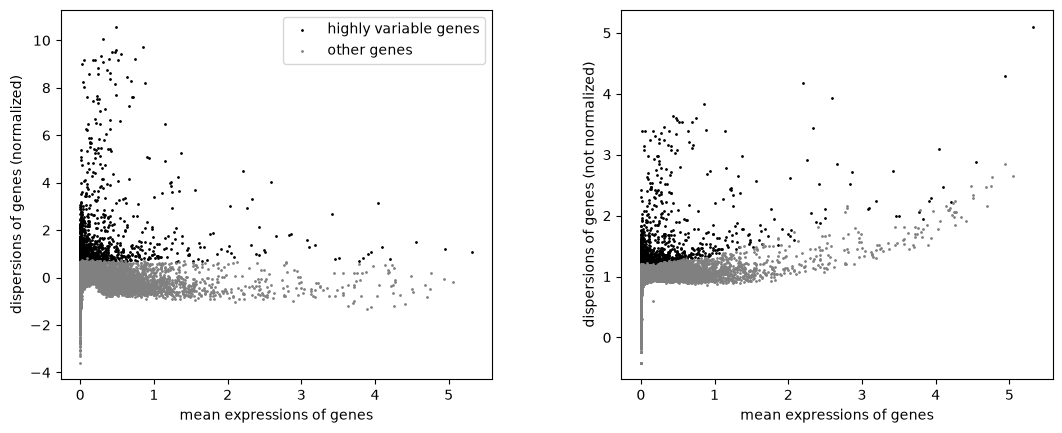

In [291]:
sc.pp.highly_variable_genes(tdata, n_top_genes=2000, batch_key="sample_id")
sc.pl.highly_variable_genes(tdata)

tdata = tdata[:, tdata_sub.var['highly_variable']].copy()

In [294]:
for res in [1,1.5,2]:
    sc.tl.leiden(
        tdata, key_added=f"leiden_res_{res:4.2f}", resolution=res, flavor="igraph"
    )

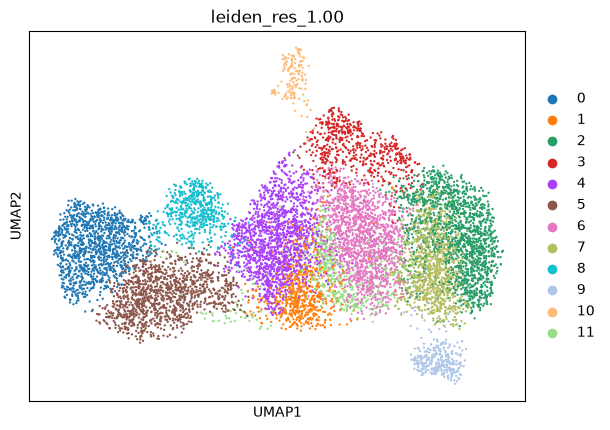

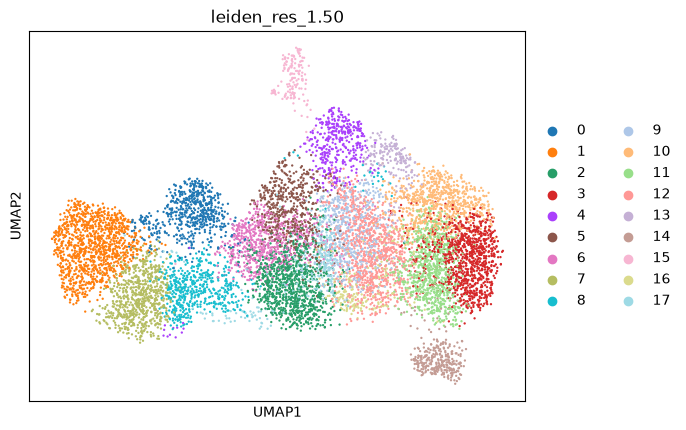

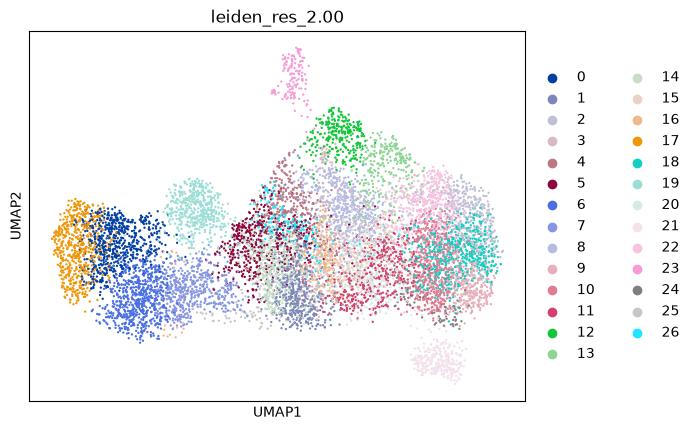

In [295]:
sc.pl.umap(tdata, color=["leiden_res_1.00"])
sc.pl.umap(tdata, color=["leiden_res_1.50"])
sc.pl.umap(tdata, color=["leiden_res_2.00"])

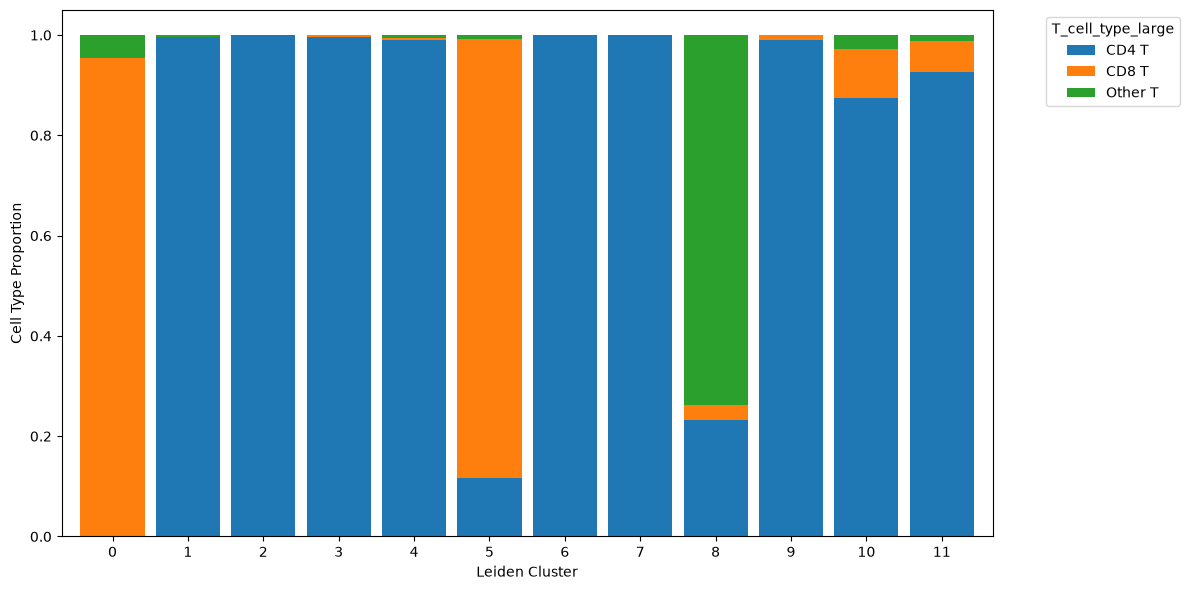

In [303]:
import pandas as pd
import matplotlib.pyplot as plt

pd.crosstab(
    tdata.obs['leiden_res_1.00'],
    tdata.obs['T_cell_type_large'],
    normalize='index'
).plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    width=0.85
)

plt.xlabel('Leiden Cluster')
plt.ylabel('Cell Type Proportion')
plt.legend(title='T_cell_type_large', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [307]:
import scanpy as sc

sc.tl.rank_genes_groups(tdata, groupby='leiden_res_1.00', method='t-test')  # 또는 'wilcoxon'
top_genes = {}

groups = tdata.uns['rank_genes_groups']['names'].dtype.names  # 클러스터 이름들

for group in groups:
    genes = tdata.uns['rank_genes_groups']['names'][group][:20]
    top_genes[group] = genes.tolist()

for cluster, genes in top_genes.items():
    print(f"Cluster {cluster}: {genes}")

Cluster 0: ['NKG7', 'GNLY', 'CCL5', 'GZMH', 'CST7', 'FGFBP2', 'PRF1', 'GZMA', 'GZMB', 'CTSW', 'S100A4', 'CD8A', 'KLRD1', 'PFN1', 'ZEB2', 'LGALS1', 'PLEK', 'CD8B', 'KLRG1', 'CX3CR1']
Cluster 1: ['RPLP0', 'LTB', 'RPLP1', 'S100A4', 'TPT1', 'IL7R', 'AQP3', 'S100A11', 'CRIP1', 'CCR6', 'TNFRSF4', 'PDE4D', 'KLRB1', 'ANXA1', 'AL136456.1', 'RORA', 'S100A10', 'LGALS3', 'FRY', 'PTPN13']
Cluster 2: ['CCR7', 'LEF1', 'SELL', 'LTB', 'FHIT', 'RPLP1', 'TPT1', 'IL6ST', 'BACH2', 'FOXP1', 'TSHZ2', 'BCL2', 'MAML2', 'CAMK4', 'RPLP0', 'TGFBR2', 'IL7R', 'RIPOR2', 'PLCL1', 'PRKCA']
Cluster 3: ['FOXP3', 'CTLA4', 'SELL', 'IKZF2', 'RTKN2', 'STAM', 'TIGIT', 'PLCL1', 'IL2RA', 'LEF1', 'CASK', 'IL32', 'IL10RA', 'SKAP1', 'S100A10', 'F5', 'CYTOR', 'DUSP16', 'SMCHD1', 'LGALS3']
Cluster 4: ['S100A4', 'IL7R', 'S100A10', 'ANXA1', 'S100A11', 'CRIP1', 'LTB', 'AHNAK', 'ITGB1', 'ANXA2', 'IL32', 'LGALS1', 'ZFP36L2', 'TAGLN2', 'ARHGAP15', 'LGALS3', 'CRIP2', 'AQP3', 'LMNA', 'TNFRSF4']
Cluster 5: ['CCL5', 'CST7', 'NKG7', 'CD8A', '

... storing 'subtype' as categorical


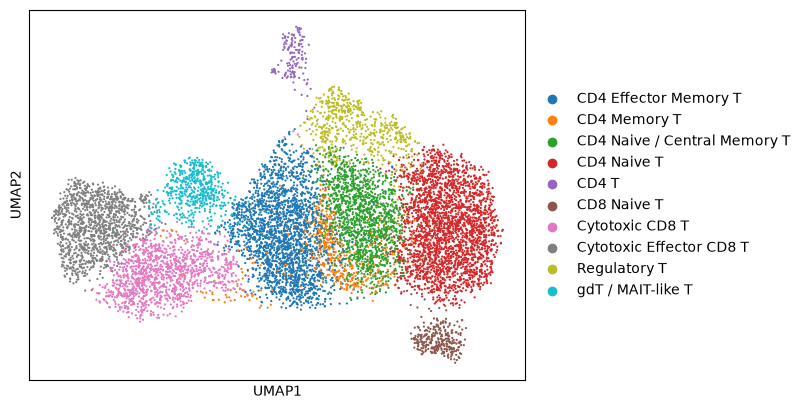

In [340]:
import scanpy as sc

cluster_to_group = {
    0: "Cytotoxic Effector CD8 T",
    1: "CD4 Effector Memory T",
    2: "CD4 Naive T",
    3: "Regulatory T",
    4: "CD4 Effector Memory T",
    5: "Cytotoxic CD8 T",
    6: "CD4 Naive / Central Memory T",
    7: "CD4 Naive T",
    8: "gdT / MAIT-like T",
    9: "CD8 Naive T",
    10: "CD4 T",
    11: "CD4 Memory T"
}

tdata.obs["subtype"] = (
    tdata.obs["leiden_res_1.00"].astype(int).map(cluster_to_group)
)

sc.pl.umap(
    tdata,
    color="subtype",
    title="",
    s=10)

In [312]:
import scanpy as sc

sc.tl.rank_genes_groups(tdata, groupby='subtype', method='t-test')  # 또는 'wilcoxon'
top_genes = {}

groups = tdata.uns['rank_genes_groups']['names'].dtype.names  # 클러스터 이름들

for group in groups:
    genes = tdata.uns['rank_genes_groups']['names'][group][:20]
    top_genes[group] = genes.tolist()

for cluster, genes in top_genes.items():
    print(f"Cluster {cluster}: {genes}")

Cluster CD4 Effector Memory T: ['S100A4', 'IL7R', 'LTB', 'S100A11', 'CRIP1', 'ANXA1', 'S100A10', 'AHNAK', 'ITGB1', 'RPLP0', 'ANXA2', 'AQP3', 'TNFRSF4', 'CCR6', 'LGALS3', 'IL32', 'TAGLN2', 'RPLP1', 'TPT1', 'CRIP2']
Cluster CD4 Memory T: ['SELL', 'LTB', 'ARHGAP15', 'RPLP1', 'IL7R', 'INPP4B', 'GATA3', 'ANXA1', 'TPT1', 'RPLP0', 'ZFP36L2', 'ITGB1', 'SNED1', 'SESN3', 'CRIP1', 'SORL1', 'S100A11', 'TAGLN2', 'CAMK4', 'PRKCA']
Cluster CD4 Naive / Central Memory T: ['LTB', 'RPLP1', 'LIMS1', 'AQP3', 'TPT1', 'PASK', 'INPP4B', 'TMSB4X', 'ARID5B', 'SELL', 'CCR7', 'TSHZ2', 'FAAH2', 'HIVEP2', 'KLRB1', 'SERINC5', 'ANK3', 'LEF1', 'FOXP1', 'SESN3']
Cluster CD4 Naive T: ['CCR7', 'LEF1', 'SELL', 'TPT1', 'LTB', 'FHIT', 'RPLP1', 'BACH2', 'IL6ST', 'FOXP1', 'TSHZ2', 'MAML2', 'TGFBR2', 'CAMK4', 'RPLP0', 'PRKCA', 'PLCL1', 'PDE7A', 'PDE3B', 'TMSB10']
Cluster CD4 T: ['MALAT1', 'PTPRC', 'ARHGAP15', 'SMCHD1', 'SKAP1', 'ZBTB20', 'MT-CO1', 'FTX', 'PAG1', 'NEAT1', 'MBNL1', 'SYNE2', 'RORA', 'ANKRD44', 'RIPOR2', 'CELF2', 

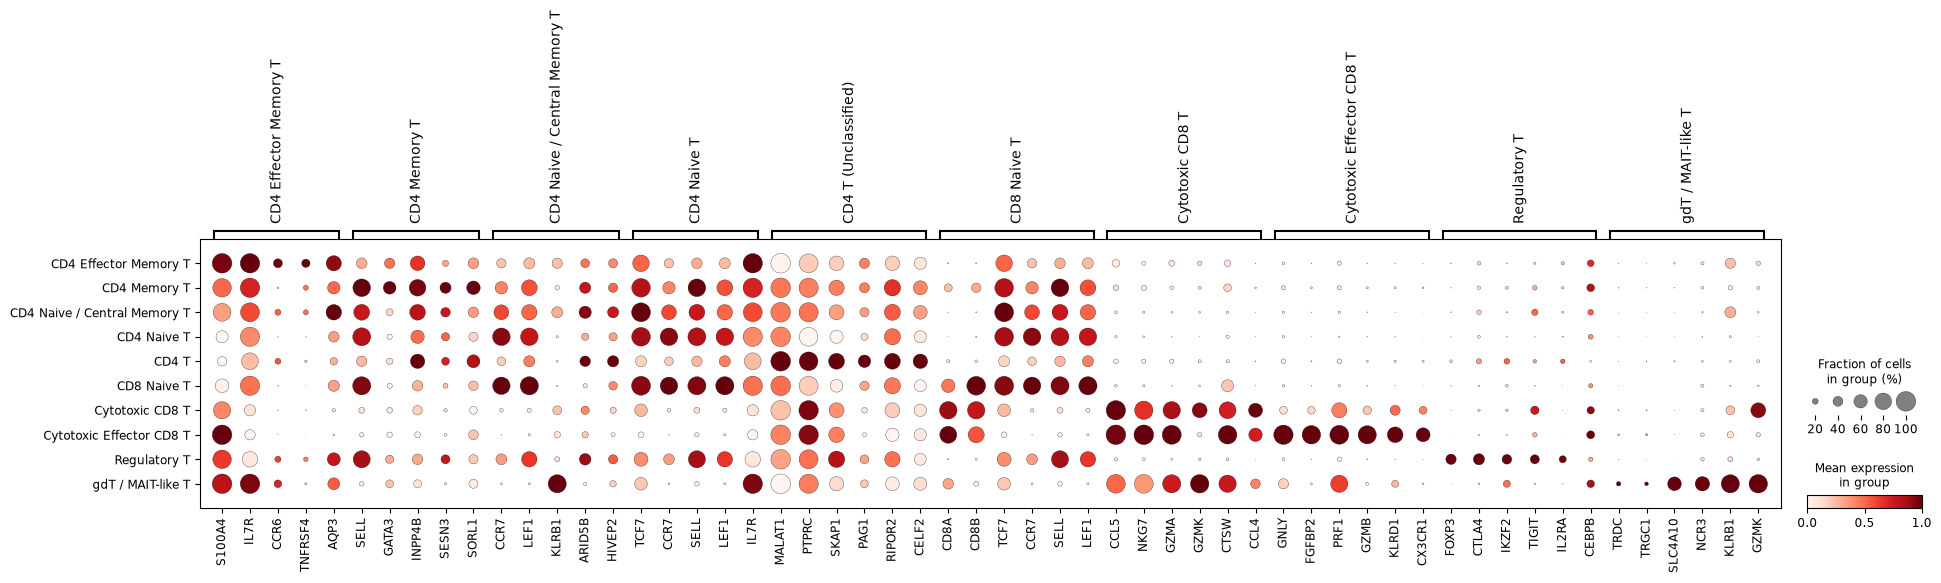

In [351]:
PBMC_subtype_markers_human = {
    "CD4 Effector Memory T": ["S100A4", "IL7R", "CCR6", "TNFRSF4", "AQP3"],
    "CD4 Memory T": ["SELL", "GATA3", "INPP4B", "SESN3", "SORL1"],
    "CD4 Naive / Central Memory T": ["CCR7", "LEF1", "KLRB1", "ARID5B", "HIVEP2"],
    "CD4 Naive T": ["TCF7", "CCR7", "SELL", "LEF1", "IL7R"],
    "CD4 T (Unclassified)": ["MALAT1", "PTPRC", "SKAP1", "PAG1", "RIPOR2", "CELF2"],
    "CD8 Naive T": ["CD8A", "CD8B", "TCF7", "CCR7", "SELL", "LEF1"],
    "Cytotoxic CD8 T": ["CCL5", "NKG7", "GZMA", "GZMK", "CTSW", "CCL4"],
    "Cytotoxic Effector CD8 T": ["GNLY", "FGFBP2", "PRF1", "GZMB", "KLRD1", "CX3CR1"],
    "Regulatory T": ["FOXP3", "CTLA4", "IKZF2", "TIGIT", "IL2RA", "CEBPB"],
    "gdT / MAIT-like T": ["TRDC", "TRGC1", "SLC4A10", "NCR3", "KLRB1", "GZMK"]
}

existing_subtype_markers = {
    subtype: [gene for gene in genes if gene in tdata_sub.var_names]
    for subtype, genes in PBMC_subtype_markers_human.items()
}

existing_subtype_markers = {
    subtype: genes
    for subtype, genes in existing_subtype_markers.items()
    if len(genes) > 0
}

sc.pl.dotplot(
    tdata_sub,
    var_names=existing_subtype_markers,
    groupby="subtype",
    standard_scale="var",
    dendrogram=False,
    swap_axes=False
)

In [334]:
common_cells = tdata.obs_names[tdata.obs_names.isin(bdata.obs_names)]

tdata_sub = bdata[common_cells].copy()
tdata_sub.obs = tdata.obs.loc[common_cells].copy()
tdata_sub.uns = tdata.uns.copy()
tdata_sub.obsm = tdata.obsm.copy()
tdata_sub.obsp = tdata.obsp.copy()

In [343]:
tdata_sub.write_h5ad("/home/Data_Drive_8TB/kykim/8. RL/tdata_sub.h5ad")

In [350]:
tdata_sub.obs['subtype'].value_counts()

subtype
CD4 Naive T                     2567
CD4 Effector Memory T           2183
CD4 Naive / Central Memory T    1474
Cytotoxic Effector CD8 T        1209
Cytotoxic CD8 T                 1204
Regulatory T                     585
CD4 Memory T                     550
gdT / MAIT-like T                540
CD8 Naive T                      306
CD4 T                            144
Name: count, dtype: int64